In [33]:

import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import keras


In [34]:

IMG_SIZE = (256, 256)
IMAGES_DIR = "../data/images"
MASKS_DIR = "../data/masks"
CSV_PATH = "../data/GroundTruth.csv"
MASKS_CSV_PATH = "../data/GroundTruth_masks.csv"


In [35]:

metadata = pd.read_csv(CSV_PATH)

if "mask" not in metadata.columns:
    metadata.insert(1, "mask", metadata["image"].astype(str) + "_segmentation")

metadata.to_csv(MASKS_CSV_PATH, index=False)
print(metadata.head())


          image                       mask  MEL   NV  BCC  AKIEC  BKL   DF  \
0  ISIC_0024306  ISIC_0024306_segmentation  0.0  1.0  0.0    0.0  0.0  0.0   
1  ISIC_0024307  ISIC_0024307_segmentation  0.0  1.0  0.0    0.0  0.0  0.0   
2  ISIC_0024308  ISIC_0024308_segmentation  0.0  1.0  0.0    0.0  0.0  0.0   
3  ISIC_0024309  ISIC_0024309_segmentation  0.0  1.0  0.0    0.0  0.0  0.0   
4  ISIC_0024310  ISIC_0024310_segmentation  1.0  0.0  0.0    0.0  0.0  0.0   

   VASC  
0   0.0  
1   0.0  
2   0.0  
3   0.0  
4   0.0  


In [36]:

classes = ["MEL", "NV", "BCC", "AKIEC", "BKL", "DF", "VASC"]
class_code = {label: code for code, label in enumerate(classes)}
class_name = {code: label for code, label in enumerate(classes)}


In [37]:

def find_file(directory, base_name, extensions):
    for extension in extensions:
        path = os.path.join(directory, base_name + extension)
        if os.path.exists(path):
            return path
    return None


def prepare_metadata_with_paths(images_dir, masks_dir, metadata, class_code):
    rows = []

    for _, row in metadata.iterrows():
        image_name = str(row["image"])
        mask_name = str(row["mask"])

        image_path = find_file(images_dir, image_name, [".jpg", ".jpeg", ".png"])
        mask_path = find_file(masks_dir, mask_name, [".png", ".jpg", ".jpeg"])

        if image_path is None or mask_path is None:
            continue

        class_label = row[classes].idxmax()
        coded_label = class_code[class_label]

        rows.append({
            "image": image_name,
            "mask": mask_name,
            "image_path": image_path,
            "mask_path": mask_path,
            "label": coded_label,
            "class_name": class_label
        })

    return pd.DataFrame(rows)


prepared_metadata = prepare_metadata_with_paths(
    IMAGES_DIR,
    MASKS_DIR,
    metadata,
    class_code
)

print(prepared_metadata.head())
print("Quantidade de pares imagem-máscara encontrados:", len(prepared_metadata))


          image                       mask                       image_path  \
0  ISIC_0024306  ISIC_0024306_segmentation  ../data/images/ISIC_0024306.jpg   
1  ISIC_0024307  ISIC_0024307_segmentation  ../data/images/ISIC_0024307.jpg   
2  ISIC_0024308  ISIC_0024308_segmentation  ../data/images/ISIC_0024308.jpg   
3  ISIC_0024309  ISIC_0024309_segmentation  ../data/images/ISIC_0024309.jpg   
4  ISIC_0024310  ISIC_0024310_segmentation  ../data/images/ISIC_0024310.jpg   

                                     mask_path  label class_name  
0  ../data/masks/ISIC_0024306_segmentation.png      1         NV  
1  ../data/masks/ISIC_0024307_segmentation.png      1         NV  
2  ../data/masks/ISIC_0024308_segmentation.png      1         NV  
3  ../data/masks/ISIC_0024309_segmentation.png      1         NV  
4  ../data/masks/ISIC_0024310_segmentation.png      0        MEL  
Quantidade de pares imagem-máscara encontrados: 10015


In [38]:

def load_image_mask_and_segmented(image_path, mask_path, image_size):
    original = keras.utils.load_img(
        image_path,
        target_size=image_size,
        color_mode="rgb"
    )
    original = keras.utils.img_to_array(original).astype("float32")

    mask = keras.utils.load_img(
        mask_path,
        target_size=image_size,
        color_mode="grayscale"
    )
    mask = keras.utils.img_to_array(mask).astype("float32") / 255.0
    mask = (mask > 0.5).astype("float32")

    segmented = original * mask

    return original, mask, segmented


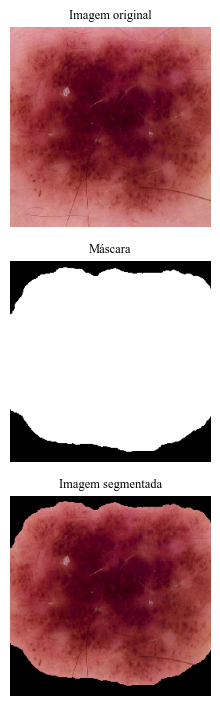

Figura salva como: exemplo_segmentacao_vertical.png
Classe: NV
Imagem: ISIC_0026036
Máscara: ISIC_0026036_segmentation


In [ ]:
# Padronização visual da figura para o artigo
plt.rcParams["font.family"] = "serif"
plt.rcParams["font.serif"] = ["Times New Roman", "Times", "DejaVu Serif"]
plt.rcParams["font.size"] = 15

TARGET_CLASS = "NV"
RANDOM_STATE = 42

if TARGET_CLASS is None:
    sample = prepared_metadata.sample(1, random_state=RANDOM_STATE).iloc[0]
else:
    sample = prepared_metadata[prepared_metadata["class_name"] == TARGET_CLASS].sample(
        1,
        random_state=RANDOM_STATE
    ).iloc[0]

original, mask, segmented = load_image_mask_and_segmented(
    sample["image_path"],
    sample["mask_path"],
    IMG_SIZE
)

fig, axes = plt.subplots(3, 1, figsize=(3.0, 7.2))

axes[0].imshow(original.astype("uint8"))
axes[0].set_title("Imagem original", fontsize=9)
axes[0].axis("off")

axes[1].imshow(mask.squeeze(), cmap="gray")
axes[1].set_title("Máscara", fontsize=9)
axes[1].axis("off")

axes[2].imshow(segmented.astype("uint8"))
axes[2].set_title("Imagem segmentada", fontsize=9)
axes[2].axis("off")

plt.tight_layout(pad=0.8)

plt.savefig(
    "exemplo_segmentacao_vertical.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figura salva como: exemplo_segmentacao_vertical.png")
print("Classe:", sample["class_name"])
print("Imagem:", sample["image"])
print("Máscara:", sample["mask"])


## Mosaico com vários exemplos

A célula abaixo gera um mosaico com vários exemplos, o que pode ser útil para inspeção visual ou seleção manual da figura que será usada no artigo.


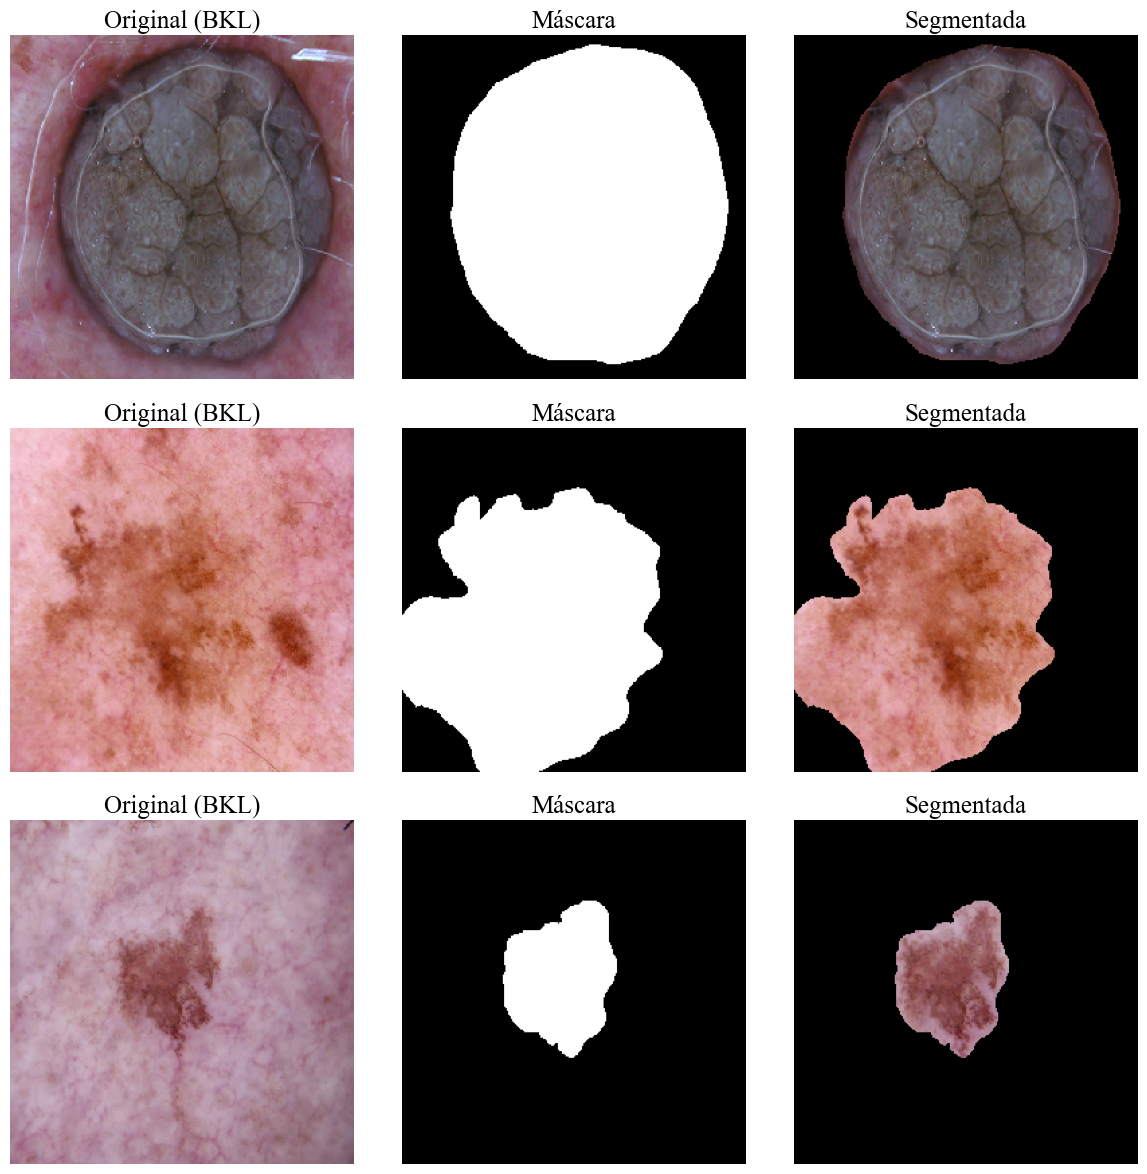

Figura salva como: mosaico_segmentacao.png


In [ ]:

N_EXAMPLES = 3  
RANDOM_STATE = 123

samples = prepared_metadata.sample(N_EXAMPLES, random_state=RANDOM_STATE).reset_index(drop=True)

fig, axes = plt.subplots(N_EXAMPLES, 3, figsize=(12, 4 * N_EXAMPLES))

if N_EXAMPLES == 1:
    axes = np.expand_dims(axes, axis=0)

for i, row in samples.iterrows():
    original, mask, segmented = load_image_mask_and_segmented(
        row["image_path"],
        row["mask_path"],
        IMG_SIZE
    )

    axes[i, 0].imshow(original.astype("uint8"))
    axes[i, 0].set_title(f"Original ({row['class_name']})")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(mask.squeeze(), cmap="gray")
    axes[i, 1].set_title("Máscara")
    axes[i, 1].axis("off")

    axes[i, 2].imshow(segmented.astype("uint8"))
    axes[i, 2].set_title("Segmentada")
    axes[i, 2].axis("off")

plt.tight_layout()
plt.savefig("mosaico_segmentacao.png", dpi=300, bbox_inches="tight")
plt.show()

print("Figura salva como: mosaico_segmentacao.png")
